In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

header = ['comment_id', 'text', 'date', 'song', 'artist', 'kendrick_score', 'drake_score']
dataset = pd.read_csv(filepath_or_buffer='./cleaned_comments/cleaned_comments.csv',  delimiter=',', names=header, skiprows=1)
dataset

,comment_id,text,date,song,artist,kendrick_score,drake_score
0,Ugzc5Srhx8p6qzdSjvB4AaABAg,Kendrick responded so fast I didnt know Drake ...,2024-05-04 12:59:37+00:00,Family_Matters,BagOnly_Drake,2,-1
1,UgxGl-mJYHo4mzjNy0R4AaABAg,Beat switches each time a different ghost writ...,2024-05-04 08:41:23+00:00,Family_Matters,BagOnly_Drake,0,-2
2,Ugw8sI-rRjgKXTUCBFV4AaABAg,Kendrick had a diss ready for this song not ev...,2024-05-04 05:18:35+00:00,Family_Matters,BagOnly_Drake,2,0
3,UgzkG6vRyh2O9FOlnJR4AaABAg,Imagine sitting down in a group and writing th...,2024-05-04 17:04:41+00:00,Family_Matters,BagOnly_Drake,1,-1
4,UgyRU5sH2RugrPSNal94AaABAg,ngl Drake's melody is fire\n\nbut Kendrick's l...,2024-05-05 06:28:06+00:00,Family_Matters,BagOnly_Drake,3,2
...,...,...,...,...,...,...,...
5693,Ugy_pfO-XFQhO5gGBA94AaABAg,"''I agree'' with you, this track is so deep th...",2024-05-05 10:59:39+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5694,UgwKaRbSQ7CT8Id9UlJ4AaABAg,"It's like y'all came in expecting a comedy, wa...",2024-05-04 21:19:33+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,-3
5695,UgwKuRsl6mRT319BxZB4AaABAg,Kendrick gave you all the bars and metaphors y...,2024-05-05 05:00:26+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,3,0
5696,UgxGzHrFJUiB4cJv-7t4AaABAg,Never thought I would think this channel would...,2024-05-04 22:54:04+00:00,Meet_the_Grahams,LostInVegas_Kendrick_Lamar,2,-2


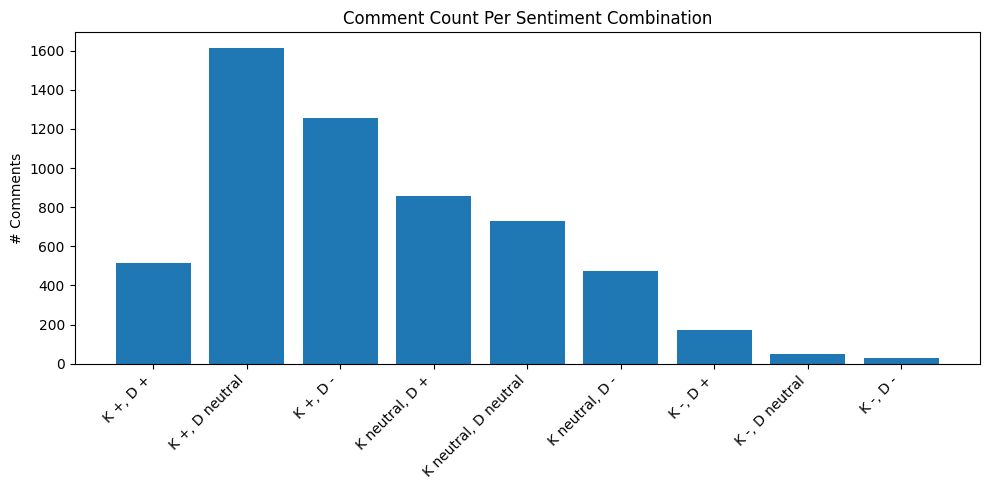

In [2]:
#pulling together the same labeled data as the naive bayes -- I think trying to 
#fit how I originally wanted to (to predict each combination) is again slicing too
#fine. so we'll see how the coarser method works

signs = {1: '+', 0: 'neutral', -1: '-'}

k_signs = np.sign(dataset['kendrick_score']).astype(int).map(signs)
d_signs = np.sign(dataset['drake_score']).astype(int).map(signs)

youtube_comment_texts = dataset['text'].to_numpy(dtype=object)
youtube_comment_labels = ('K ' + k_signs + ', D ' + d_signs).to_numpy(dtype=object)

order = ['+', 'neutral', '-']
all_labels = [f"K {k}, D {d}" for k in order for d in order]

counts = pd.Series(youtube_comment_labels).value_counts().reindex(all_labels, fill_value=0)

plt.figure(figsize=(10, 5))
plt.bar(counts.index, counts.values)
plt.xticks(rotation=45, ha='right')
plt.ylabel('# Comments')
plt.title('Comment Count Per Sentiment Combination')
plt.tight_layout()
plt.show()

In [30]:
def evaluate(model, X_part, y_part):
    predictions = model.predict(X_part)
    return {'accuracy': accuracy_score(y_part, predictions)}

### Evaluating best split percentage

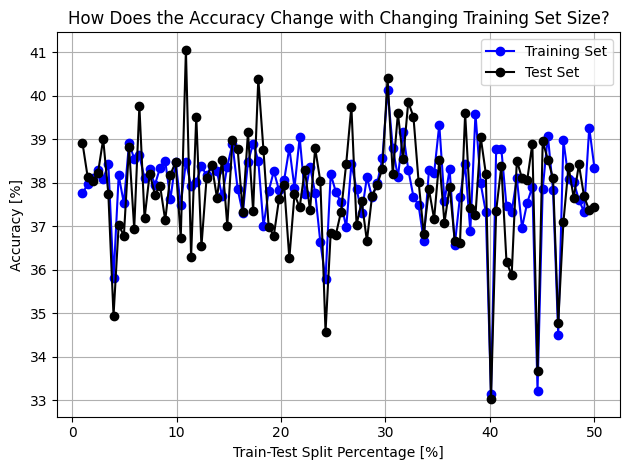

In [ ]:
#how does the accuracy change with test size? what is the optimal test size?
ttsplit_percentage = np.linspace(0.01, 0.5, num=100, endpoint=True)
n_estimators = 190
random_state = 256

accuracies_val = []
accuracies_train = []
for split_percentage in ttsplit_percentage:
    X_build, X_test, y_build, y_test = train_test_split(youtube_comment_texts,
                                                    youtube_comment_labels,
                                                    test_size=split_percentage,
                                                    random_state=random_state)

    X_train, X_val, y_train, y_val = train_test_split(
        X_build, y_build, test_size=0.25, stratify=y_build, random_state=random_state)

    #vectorizing
    vec = CountVectorizer()
    X_train_vec = vec.fit_transform(X_train)
    X_val_vec = vec.transform(X_val)

    ABmodel = AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1),
            learning_rate=1.0, 
            random_state=random_state,
            n_estimators=n_estimators,
            # algorithm='SAMME',
        )
    ABmodel.fit(X_train_vec, y_train)

    AB_val_result = evaluate(ABmodel, X_val_vec, y_val)
    accuracies_val.append(AB_val_result['accuracy'])
    accuracies_train.append(evaluate(ABmodel, X_train_vec, y_train)['accuracy'])

accuracies_train = np.asarray(accuracies_train)
accuracies_val = np.asarray(accuracies_val)

plt.figure()
plt.plot(ttsplit_percentage*100, accuracies_train*100, marker='o', ls='-', c='blue', label='Training Set')
plt.plot(ttsplit_percentage*100, accuracies_val*100, marker='o', ls='-', c='black', label='Validation Set')
plt.ylabel("Accuracy [%]")
plt.xlabel("Train-Test Split Percentage [%]")
plt.title("How Does the Accuracy Change with Changing Training Set Size?")
plt.tight_layout()
plt.legend()
plt.grid(True)
plt.show()


In [33]:
split_idx = np.argmax(accuracies_val)
print(split_idx, accuracies_val[split_idx]*100, ttsplit_percentage[split_idx]*100)

20 41.05594956658786 10.898989898989898


### Evaluating best learning rate

In [35]:
split_percentage = ttsplit_percentage[split_idx]

#building train, validation, and test splits
X_build, X_test, y_build, y_test = train_test_split(youtube_comment_texts,
                                                    youtube_comment_labels,
                                                    test_size=split_percentage,
                                                    random_state=random_state)

X_train, X_val, y_train, y_val = train_test_split(
    X_build, y_build, test_size=0.25, stratify=y_build, random_state=random_state)

#vectorizing
vec = CountVectorizer()
X_train_vec = vec.fit_transform(X_train)
X_test_vec = vec.transform(X_test)
X_val_vec = vec.transform(X_val)

[0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75
 0.8  0.85 0.9  0.95 1.  ]


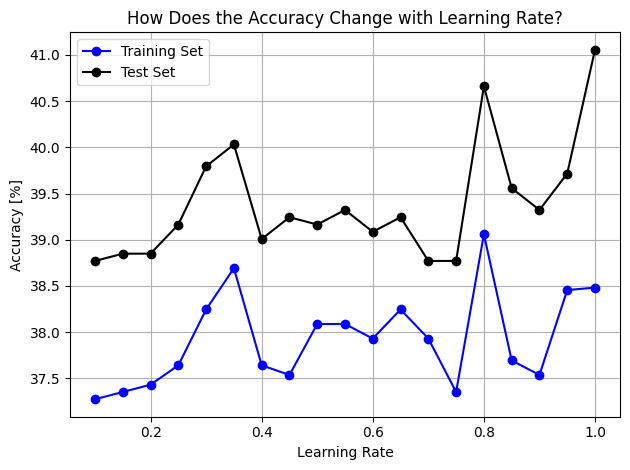

In [ ]:
learning_rates = np.linspace(0.1, 1, num=19, endpoint=True, dtype=float)
print(learning_rates)

accuracies_val = []
accuracies_train = []
for learning_rate in learning_rates:
    X_build, X_test, y_build, y_test = train_test_split(youtube_comment_texts,
                                                    youtube_comment_labels,
                                                    test_size=split_percentage,
                                                    random_state=random_state)

    X_train, X_val, y_train, y_val = train_test_split(
        X_build, y_build, test_size=0.25, stratify=y_build, random_state=random_state)

    #vectorizing
    vec = CountVectorizer()
    X_train_vec = vec.fit_transform(X_train)
    X_val_vec = vec.transform(X_val)

    ABmodel = AdaBoostClassifier(
            estimator=DecisionTreeClassifier(max_depth=1),
            learning_rate=learning_rate, 
            random_state=random_state,
            n_estimators=n_estimators,
            # algorithm='SAMME',
        )
    ABmodel.fit(X_train_vec, y_train)

    AB_val_result = evaluate(ABmodel, X_val_vec, y_val)
    accuracies_val.append(AB_val_result['accuracy'])
    accuracies_train.append(evaluate(ABmodel, X_train_vec, y_train)['accuracy'])

accuracies_train = np.asarray(accuracies_train)
accuracies_val = np.asarray(accuracies_val)

plt.figure()
plt.plot(learning_rates, accuracies_train*100, marker='o', ls='-', c='blue', label='Training Set')
plt.plot(learning_rates, accuracies_val*100, marker='o', ls='-', c='black', label='Validation Set')
plt.ylabel("Accuracy [%]")
plt.xlabel("Learning Rate")
plt.title("How Does the Accuracy Change with Learning Rate?")
plt.tight_layout()
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
learning_idx = np.argmax(accuracies_val)
print(learning_idx, accuracies_val[learning_idx]*100, learning_rates[learning_idx])

18 41.05594956658786 1.0


### Evaluating the number of estimators

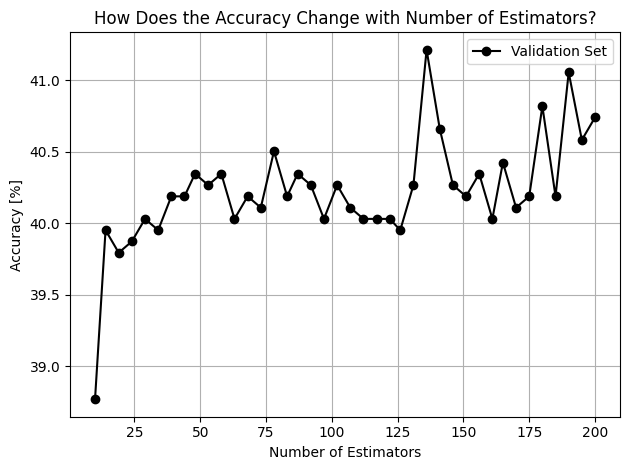

In [43]:
estimator_number = np.linspace(10, 200, num=40, endpoint=True, dtype=int)
learning_rate = learning_rates[learning_idx]
split_percentage = ttsplit_percentage[split_idx]

X_build, X_test, y_build, y_test = train_test_split(youtube_comment_texts,
                                                    youtube_comment_labels,
                                                    test_size=split_percentage,
                                                    random_state=random_state)

X_train, X_val, y_train, y_val = train_test_split(
    X_build, y_build, test_size=0.25, stratify=y_build, random_state=random_state)


nest_accuracies = []
for n_estimator in estimator_number:
    ABmodel = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        learning_rate=learning_rate, 
        random_state=random_state,
        n_estimators=n_estimator,
        # algorithm='SAMME',
    )
    ABmodel.fit(X_train_vec, y_train)

    AB_val_result = evaluate(ABmodel, X_val_vec, y_val)
    nest_accuracies.append(AB_val_result['accuracy'])
    # print(f"AdaBoost with n_estimators = {n_estimator}")
    # print(f"Validation accuracy: {AB_val_result['accuracy']*100}%")
    # print(f"Validation F1 for cancerous class: {AB_val_result['F1']}")

nest_accuracies = np.asarray(nest_accuracies)

plt.figure()
plt.plot(estimator_number, nest_accuracies*100, marker='o', ls='-', c='black', label='Validation Set')
plt.ylabel("Accuracy [%]")
plt.xlabel("Number of Estimators")
plt.title("How Does the Accuracy Change with Number of Estimators?")
plt.tight_layout()
plt.legend()
plt.grid(True)
plt.show()

In [44]:
estimator_idx = np.argmax(nest_accuracies)
print(estimator_idx, nest_accuracies[estimator_idx], estimator_number[estimator_idx])

26 0.41213553979511425 136


In [47]:
#best model based off above tests
n_estimators = estimator_number[estimator_idx] #179
learning_rate = learning_rates[learning_idx]
test_split_percentage = ttsplit_percentage[split_idx] #10.90%
val_split_percentage = 0.25

X_build, X_test, y_build, y_test = train_test_split(youtube_comment_texts,
                                                    youtube_comment_labels,
                                                    test_size=test_split_percentage,
                                                    random_state=random_state)

X_train, X_val, y_train, y_val = train_test_split(
    X_build, y_build, test_size=val_split_percentage, stratify=y_build, random_state=random_state)

#vectorizing
vec = CountVectorizer()
X_train_vec = vec.fit_transform(X_train)
X_val_vec = vec.transform(X_val)
X_test_vec = vec.transform(X_test)


bestABmodel = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1),
        learning_rate=learning_rate, 
        random_state=random_state,
        n_estimators=n_estimators,
        # algorithm='SAMME',
    )
bestABmodel.fit(X_train_vec, y_train)

bestAB_val_result = evaluate(bestABmodel, X_val_vec, y_val)
print(bestAB_val_result)

bestAB_test_result = evaluate(bestABmodel, X_test_vec, y_test)
print(bestAB_test_result)

{'accuracy': 0.41213553979511425}
{'accuracy': 0.39228295819935693}


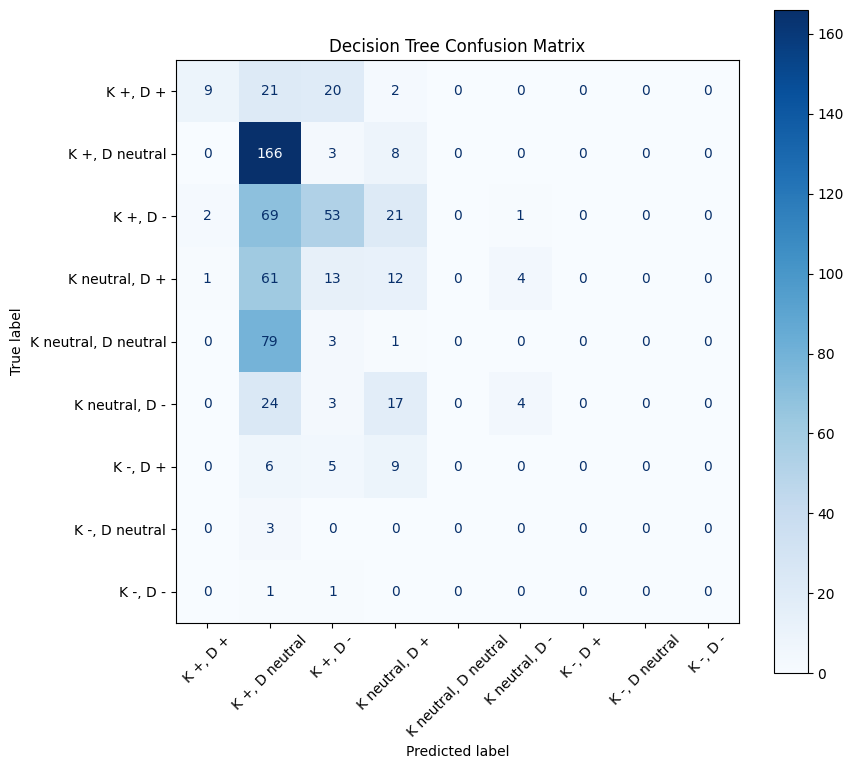

                      precision    recall  f1-score   support

            K +, D +       0.75      0.17      0.28        52
      K +, D neutral       0.39      0.94      0.55       177
            K +, D -       0.52      0.36      0.43       146
      K neutral, D +       0.17      0.13      0.15        91
K neutral, D neutral       0.00      0.00      0.00        83
      K neutral, D -       0.44      0.08      0.14        48
            K -, D +       0.00      0.00      0.00        20
      K -, D neutral       0.00      0.00      0.00         3
            K -, D -       0.00      0.00      0.00         2

            accuracy                           0.39       622
           macro avg       0.25      0.19      0.17       622
        weighted avg       0.36      0.39      0.31       622



In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report


y_pred = bestABmodel.predict(X_test_vec)

cm = confusion_matrix(y_test, y_pred, labels=all_labels)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=all_labels).plot(
    ax=ax, cmap='Blues', xticks_rotation=45
)
plt.title('Decision Tree Confusion Matrix')
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, labels=all_labels, zero_division=0))